# Travelling Salesman Problem:

The **Travelling Salesman Problem (TSP)** is a classic optimization problem in computer science and operations research. This problem is to find the shortest path following the two important constraints which are 

1. One city/place should be visited only once.

2. Should visit all cities/places and return back to starting point.

TSP can be represented using a graph where cities are nodes and distances between cities are edges. The challenge is to determine the optimal tour with minimum total travel cost or distance.

The problem is classified as an **NP-hard** problem, meaning that as the number of cities increases, the number of possible routes grows factorially, making it computationally difficult to solve using brute-force methods. 


**TSP** has many real-world applications, including:

1. Logistics and delivery route optimization

2. Vehicle routing systems

3. Robotics path planning

4. Circuit board manufacturing

5. Network optimization


Several approaches are used to solve **TSP**, such as:

- Brute Force

- Dynamic Programming

- Branch and Bound

- Genetic Algorithms

- Ant Colony Optimization

- Quantum algorithms like QAOA and VQE

> Because of its importance and complexity, TSP is widely studied in classical and quantum computing research.

## Example:

![4-Node Map](TSP-4Node.jpg)

Consider the above map, where $4$ cities $A,B,C,D$ are represented as the $4$ nodes of a graph. The edges connecting the nodes are bi-directional, meaning that travel is possible in both directions between any two connected cities.

Now, let us assign weights to these edges. These weights can represent either the distance between the nodes or the cost of travel. The weights are represented using a cost matrix, and the following matrix is considered as an example:

$$ {costmatrix}\ =\begin{bmatrix}0 & 16 & 11 & 6 \\ 8 & 0 & 13 & 16 \\ 4 & 7 & 0 & 9 \\ 5 & 12 & 2 & 0 \end{bmatrix}$$ 

These are the weights of edges of the 4 node graph formed above which can be represented as follows:

![4 Node Graph with Weights](4Node_with_Weights.drawio.png)

- The matrix weights are mapped as follows:

$$ \boxed{\begin{array}{c|cccc}
 & \textcolor{red}{A} & \textcolor{green}{B} & \textcolor{blue}{C} & \textcolor{magenta}{D} \\
\hline
\textcolor{red}{A} & 0 & 16 & 11 & 6 \\
\textcolor{green}{B} & 8 & 0 & 13 & 16 \\
\textcolor{blue}{C} & 4 & 7 & 0 & 9 \\
\textcolor{magenta}{D} & 5 & 12 & 2 & 0 \\
\end{array}}$$

In [1]:
import numpy as np
import networkx as nx
import itertools
import math
import time
import random
from functools import lru_cache
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from scipy.optimize import minimize
from IPython.display import display, Math

In [2]:
# 🔹 INPUT: Number of nodes
n = 4# <-- Change this only
print("n =",n)
    
# Generate node labels: A, B, C, ...
nodes = [chr(65 + i) for i in range(n)]
print("Nodes are: ",nodes)
    
# 🔹 Generate random cost matrix (diagonal = 0)
cost_matrix = [[0 if i == j else random.randint(1, 20) for j in range(n)] for i in range(n)]
    
print("Cost Matrix :",cost_matrix)

backend = Aer.get_backend('qasm_simulator')

n = 4
Nodes are:  ['A', 'B', 'C', 'D']
Cost Matrix : [[0, 14, 6, 1], [13, 0, 10, 13], [8, 5, 0, 19], [20, 11, 1, 0]]


## Classical baseline — brute-force search

**What this code does:** tries *every possible tour* and keeps the cheapest one.

**How it works:**
1. Fix the starting city as `'A'` — for a round trip, the starting point doesn't change which
   tour is optimal, but fixing it cuts the search space from `n!` down to `(n-1)!` permutations.
2. `itertools.permutations` generates every ordering of the remaining cities.
3. For each ordering, build the full round-trip path (start → ... → start) and sum the
   edge costs from the cost matrix.
4. Track the minimum cost seen and the path that achieved it.

**Why include it:** this is the *ground truth*. For 4 cities there are only `3! = 6` tours to check, so brute force finishes in microseconds and gives us something exact to judge QAOA and VQE against. Its cost grows factorially (`(n-1)!`), which is exactly why quantum/heuristic approaches become interesting once `n` gets large — brute force stops being feasible long before either quantum algorithm would.

![](Brute_Force.png)

In [3]:
def run_brute_force(n,nodes,cost_matrix):
    start_time = time.perf_counter()
    # 🔹 Solve TSP (Brute Force)
    start = 'A'
    other_nodes = [node for node in nodes if node != start]
    
    min_cost = float('inf')
    best_path = None
    
    for perm in itertools.permutations(other_nodes):
        path = [start] + list(perm) + [start]
        
        cost = 0
        for i in range(len(path) - 1):
            u = nodes.index(path[i])
            v = nodes.index(path[i + 1])
            cost += cost_matrix[u][v]
        
        if cost < min_cost:
            min_cost = cost
            best_path = path
    
    end_time = time.perf_counter()
    print("Optimal Path:", " -> ".join(best_path))
    print("Minimum Cost:", min_cost)
    time_taken = end_time - start_time # 🔹 Duration
    print(f"Time Taken: {time_taken:.8f} seconds")
    print("********************************************")

run_brute_force(n,nodes,cost_matrix)

Optimal Path: A -> D -> C -> B -> A
Minimum Cost: 20
Time Taken: 0.00001325 seconds
********************************************


# QAOA-COBYLA Implementation:

**Big picture:** QAOA prepares a quantum superposition over candidate answers, uses a "cost circuit" to mark good answers with a phase, mixes amplitudes between candidates, repeats that `p` times, then measures. A classical optimizer (COBYLA) tunes the circuit's angles (`gamma`, `beta`) between runs to make good answers more likely.

![](qaoa_circuit.png)

**Step-by-step through the code:**

1. **Enumerate tours & assign costs** — identical idea to the brute-force cell: generate all `(n-1)!` permutations of the non-start cities and precompute each tour's cost into the `costs` array. `num_qubits = ceil(log2(num_states))` is the minimum number of qubits needed so every tour index has its own unique computational basis state (see the encoding diagram above).

2. **Cost unitary (`apply_cost_unitary`)** — for every tour index, it temporarily flips the qubits so that the *target* bitstring becomes `|11...1⟩` (using X-gates on the '0' bits), applies a multi-controlled phase gate `mcp` that adds a phase proportional to `2 * gamma * cost`, then flips the X-gates back. This is a **phase-oracle / lookup-table** implementation of the cost Hamiltonian: it directly encodes "if the state is tour #idx, apply a phase proportional to that tour's cost" — one `mcp` gate per tour, rather than a compact algebraic Hamiltonian derived from the graph structure. It is easy to build and understand, but it doesn't scale well: the number of gates grows with the number of tours (`(n-1)!`), not with the number of cities.

3. **Mixer (`apply_mixer`)** — a simple `RX(2·beta)` rotation on every qubit. This is the standard QAOA "transverse-field" mixer: it lets probability amplitude move between different basis states (i.e., between different candidate tours) so the optimizer isn't stuck on the first guess.

4. **Circuit assembly (`build_qaoa`)** — start with Hadamards on every qubit (equal superposition over all basis states, valid or not), then alternate cost-unitary → mixer, `p` times, then measure all qubits.

5. **Objective function** — this is what COBYLA actually minimizes. It runs the circuit on the simulator for 1024 shots, reads out the measured bitstring counts, converts each measured bitstring back to a tour index, and computes the **shot-weighted average cost** over only the *valid* indices (bitstrings ≥ `len(perms)` don't correspond to any real tour and are discarded from the average). Lower average cost = better parameters.

6. **Optimization loop** — `scipy.optimize.minimize(..., method="COBYLA")` repeatedly calls the objective function, adjusting `gamma`/`beta` to push the average cost down. Each call to the objective is one full quantum-circuit execution — that's why the "Number of Quantum Executions" printed at the end roughly equals the number of optimizer iterations.

7. **Final readout** — once optimization finishes, the circuit is run once more, and the single *most frequent* measured bitstring is decoded back into a tour and printed as the answer, alongside timing and parameter-count statistics.

**Watch for in the output:** QAOA is *sampling-based* (finite shots), so its reported cost can occasionally be worse than the true optimum found by brute force — that's shot noise and a finite optimizer budget (`maxiter=100`), not necessarily a flaw in the algorithm itself.

![](QAOA+COBYLA.png)

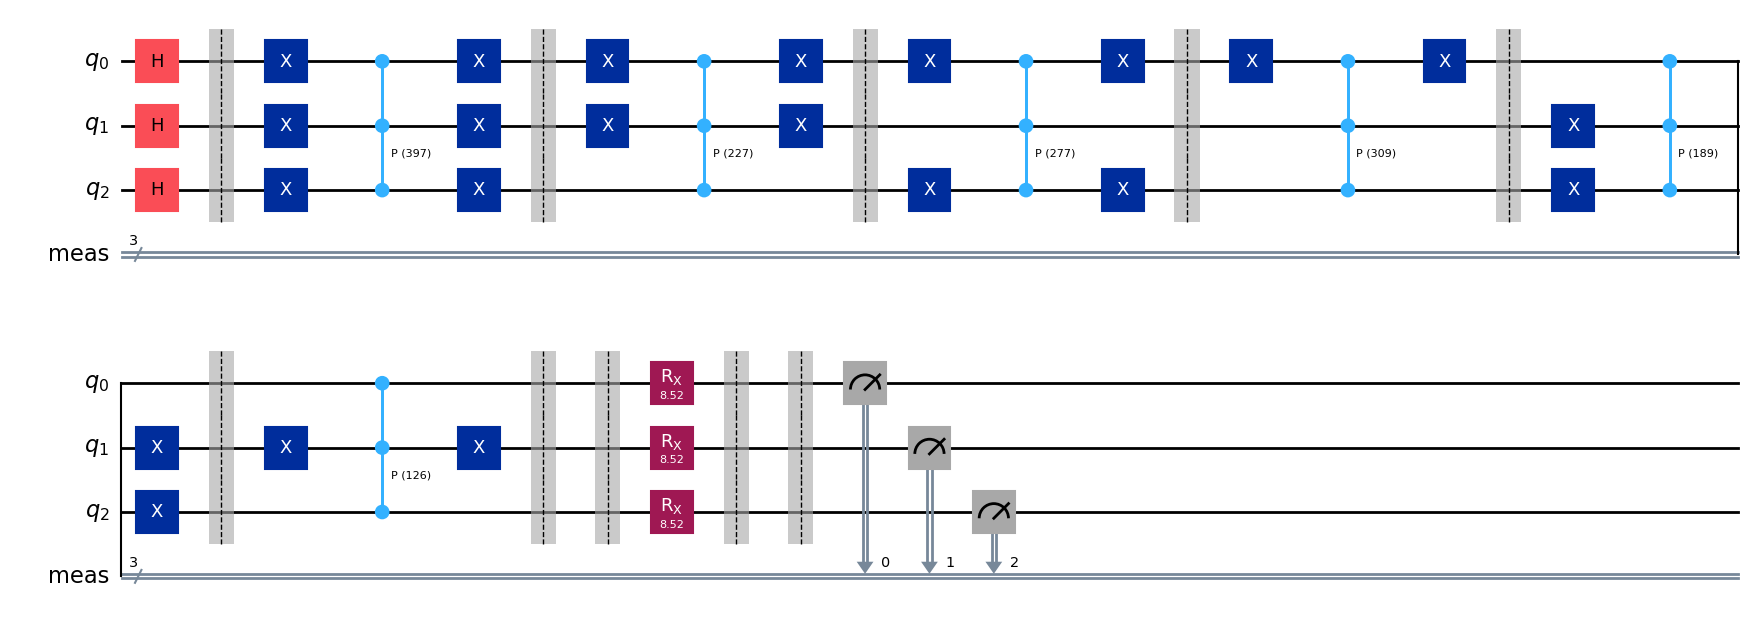

Time Taken: 0.94881273 seconds
QAOA (COBYLA, p=1) Path: A -> B -> C -> D -> A
Cost: 63
Gammas: [3.15224136]
Betas : [4.26070431]
Qubits used: 3
Number of Qubits Used: 3
Number of Gamma Parameters: 1
Number of Beta Parameters : 1
Total QAOA Parameters     : 2
Total Quantum Time (Simulator): 0.35243273 seconds
Average Quantum Time per Circuit: 0.01136880 seconds
Number of Quantum Executions: 31
********************************************


In [4]:
def run_qaoa_cobyla_p(n, nodes, cost_matrix, p=1):
    start_time = time.perf_counter()
    
    # 🔹 Generate permutations
    perms = list(itertools.permutations(range(1, n)))

    def tour_cost(perm):
        path = [0] + list(perm) + [0]
        return sum(cost_matrix[path[i]][path[i+1]] for i in range(len(path)-1))

    costs = np.array([tour_cost(p) for p in perms])

    num_states = len(perms)
    num_qubits = math.ceil(math.log2(num_states))

    # 🔹 Quantum Time Tracking
    total_quantum_time = 0.0
    all_quantum_times = []
    quantum_execution_count = 0

    # 🔹 COST UNITARY
    def apply_cost_unitary(qc, gamma):
        for idx, cost in enumerate(costs):
            bitstring = format(idx, f'0{num_qubits}b')

            for q, bit in enumerate(bitstring):
                if bit == '0':
                    qc.x(q)

            qc.mcp(2 * gamma * cost,
                   list(range(num_qubits - 1)),
                   num_qubits - 1)

            for q, bit in enumerate(bitstring):
                if bit == '0':
                    qc.x(q)

            qc.barrier()

    # 🔹 MIXER
    def apply_mixer(qc, beta):
        qc.rx(2 * beta, range(num_qubits))

    # 🔹 BUILD CIRCUIT
    def build_qaoa(params):
        gammas = params[:p]
        betas = params[p:]

        qc = QuantumCircuit(num_qubits)
        qc.h(range(num_qubits))
        qc.barrier()
        for layer in range(p):
            apply_cost_unitary(qc, gammas[layer])
            qc.barrier()
            apply_mixer(qc, betas[layer])
            qc.barrier()
        qc.measure_all()
        return qc

    # 🔹 OBJECTIVE FUNCTION (this is where MOST executions happen)
    def objective(params):
        nonlocal total_quantum_time, quantum_execution_count

        qc = build_qaoa(params)

        result = backend.run(qc, shots=1024).result()
        counts = result.get_counts()

        quantum_time = result.time_taken
        total_quantum_time += quantum_time
        all_quantum_times.append(quantum_time)
        quantum_execution_count += 1

        total_cost = 0
        total_counts = 0

        for bitstring, count in counts.items():
            idx = int(bitstring, 2)

            if idx < len(perms):
                total_cost += costs[idx] * count
                total_counts += count

        return total_cost / total_counts if total_counts > 0 else 1e9

    # 🔹 INITIAL PARAMETERS
    initial_params = np.random.rand(2 * p) * np.pi

    # 🔹 COBYLA OPTIMIZATION
    result = minimize(
        objective,
        initial_params,
        method='COBYLA',
        options={'maxiter': 100}
    )

    optimal_params = result.x
    gammas = optimal_params[:p]
    betas = optimal_params[p:]

    # 🔹 FINAL SAMPLING (extra execution)
    qc = build_qaoa(optimal_params)
    display(qc.draw("mpl"))
    result_final = backend.run(qc, shots=1000).result()
    counts = result_final.get_counts()

    quantum_time = result_final.time_taken
    total_quantum_time += quantum_time
    all_quantum_times.append(quantum_time)
    quantum_execution_count += 1

    best_state = max(counts, key=counts.get)
    idx = int(best_state, 2)

    if idx >= len(perms):
        best_perm = perms[0]
        best_cost = costs[0]
    else:
        best_perm = perms[idx]
        best_cost = costs[idx]

    # 🔹 FORMAT OUTPUT
    best_path = [0] + list(best_perm) + [0]
    best_named = [nodes[i] for i in best_path]

    end_time = time.perf_counter()

    time_taken = end_time - start_time
    print(f"Time Taken: {time_taken:.8f} seconds")

    print(f"QAOA (COBYLA, p={p}) Path:", " -> ".join(best_named))
    print("Cost:", best_cost)
    print("Gammas:", gammas)
    print("Betas :", betas)
    print("Qubits used:", num_qubits)
    # 🔹 PARAMETER INFO
    num_gammas = p
    num_betas = p
    total_params = 2 * p

    print(f"Number of Qubits Used: {num_qubits}")
    print(f"Number of Gamma Parameters: {num_gammas}")
    print(f"Number of Beta Parameters : {num_betas}")
    print(f"Total QAOA Parameters     : {total_params}")
    # 🔹 Quantum Metrics (THIS IS THE IMPORTANT PART)
    print(f"Total Quantum Time (Simulator): {total_quantum_time:.8f} seconds")
    print(f"Average Quantum Time per Circuit: {np.mean(all_quantum_times):.8f} seconds")
    print(f"Number of Quantum Executions: {quantum_execution_count}")

    print("********************************************")

run_qaoa_cobyla_p(n, nodes, cost_matrix, p=1)